# RA-Trabecular — Notebook 02: Early warning of structural collapse

**Version:** 0.2.0-dev  
**Author:** Verónica Zumpano Blumenfeld  
**ORCID:** 0009-0006-2030-1849  
**License:** Apache 2.0

**Question.** Given a *single* scan of a trabecular network — with no access to the patient's healthy baseline — can we tell how close it is to mechanical collapse?

**Set-up.**

* Each sample is a snapshot of an eroded network. Its label is the remaining erosion budget before the percolation transition, $\delta = p_c - p$.
* Features are **reference-free**: they are computed from the snapshot alone, as they would be from an HR-pQCT or micro-CT scan.
* "Individuals" differ in strut thickness, cell size, anisotropy and baseline connectivity, so neither BV/TV nor mean degree reveals $p$ trivially.
* Evaluation is grouped by individual: snapshots of the same network never appear in both training and test folds.

**Hypothesis (prediction 2 of the IRCE framework).** Connectivity descriptors carry information about proximity to failure that density descriptors do not.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ra_trabecular.ml import (
    generate_dataset, FEATURE_SETS, AT_RISK_WINDOW,
    evaluate_feature_sets, evaluate_cross_regime,
    cross_validated_predictions, fit_early_warning_model,
    permutation_importance_table,
)

RNG_SEED = 2026
N_NETWORKS = 80        # individuals; each is eroded under 3 regimes
N_JOBS = -1            # use all CPU cores
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

## 2. Synthetic dataset

In [2]:
df = generate_dataset(n_networks=N_NETWORKS, rng_seed=RNG_SEED, n_jobs=N_JOBS)
print(f"{len(df)} snapshots from {df.network_id.nunique()} individuals")
print("\nCritical erosion fraction p_c by regime:")
print(df.groupby("regime").p_c.agg(["mean", "std", "min", "max"]).round(3))
print("\nBaseline heterogeneity (healthy snapshots):")
print(df[df.p == 0][["bv_tv", "mean_degree", "gen_initial_pruning"]].describe().loc[["min", "max"]].round(3))

8880 snapshots from 80 individuals

Critical erosion fraction p_c by regime:
               mean    std    min    max
regime                                  
osteoclastic  0.504  0.054  0.368  0.618
peripheral    0.524  0.043  0.416  0.597
uniform       0.466  0.044  0.381  0.555

Baseline heterogeneity (healthy snapshots):
     bv_tv  mean_degree  gen_initial_pruning
min  0.006        2.863                0.003
max  0.052        3.783                0.247


## 3. Density vs. connectivity

Gradient-boosted regressors trained on different feature sets, with 5-fold cross-validation grouped by individual. Metrics are computed on still-connected snapshots ($\delta \ge 0$):

* **MAE** — mean absolute error of the predicted $\delta$,
* **R²** — fraction of variance in $\delta$ explained,
* **AUC** — ability to flag networks *at risk* ($0 \le \delta \le 0.10$, i.e. within 10 % of collapse).

The reference-based IRCE is included for comparison: it needs the healthy baseline, which is not available clinically.

In [3]:
sets = dict(FEATURE_SETS)
sets["mean degree only"] = ["mean_degree"]
sets["Molloy-Reed only"] = ["molloy_reed"]
sets["IRCE (needs baseline)"] = ["irce"]

results = pd.DataFrame([r.as_dict() for r in evaluate_feature_sets(df, sets)])
results = results.set_index("feature_set")[["mae_connected", "r2_connected", "auc_at_risk"]]
results.columns = ["MAE", "R2", "AUC at-risk"]
results.round(3)

,MAE,R2,AUC at-risk
feature_set,,,
density,0.131,-0.070,0.800
topology,0.033,0.918,0.981
density+topology,0.034,0.913,0.979
all,0.034,0.913,0.980
mean degree only,0.041,0.882,0.973
Molloy-Reed only,0.049,0.834,0.957
IRCE (needs baseline),0.043,0.881,0.971


## 4. Generalization to an unseen erosion regime

Train on two erosion regimes and test on the third (with disjoint individuals). A model that has learned a generic signature of approaching collapse should transfer.

In [4]:
rows = []
for name in ["density", "topology"]:
    for regime, r in evaluate_cross_regime(df, FEATURE_SETS[name]).items():
        rows.append({"features": name, "held-out regime": regime,
                     "MAE": r.mae_connected, "R2": r.r2_connected, "AUC at-risk": r.auc_at_risk})
pd.DataFrame(rows).set_index(["features", "held-out regime"]).round(3)

MAE     R2  AUC at-risk
features held-out regime                           
density  osteoclastic     0.156 -0.347        0.768
         peripheral       0.183 -0.958        0.852
         uniform          0.128 -0.146        0.788
topology osteoclastic     0.041  0.878        0.965
         peripheral       0.041  0.887        0.980
         uniform          0.062  0.716        0.979

## 5. What does the model use?

In [5]:
model = fit_early_warning_model(df, FEATURE_SETS["all"])
importance = permutation_importance_table(model, df, FEATURE_SETS["all"], n_repeats=5)
importance.round(4)

,feature,importance,std
0,mean_degree,0.0761,0.0012
1,frac_dangling,0.0424,0.0010
2,molloy_reed,0.0183,0.0003
3,mean_thickness,0.0113,0.0001
4,lcc_cycle_rank_per_edge,0.0094,0.0001
5,lcc_edge_fraction,0.0063,0.0001
6,fabric_l3,0.0041,0.0000
7,fabric_l1,0.0041,0.0001
8,n_clusters_density,0.0040,0.0001
9,a_local,0.0033,0.0001


The Molloy–Reed ratio $\kappa = \langle k^2\rangle / \langle k\rangle$ predicts a giant component in random graphs when $\kappa > 2$. Its value at the observed transition:

In [6]:
near = df[df.delta.abs() < 0.02]
print(f"kappa at p_c: {near.molloy_reed.mean():.2f} ± {near.molloy_reed.std():.2f}")
print(f"kappa healthy: {df[df.p == 0].molloy_reed.mean():.2f}")

kappa at p_c: 2.48 ± 0.15
kappa healthy: 3.53


## 6. Figure

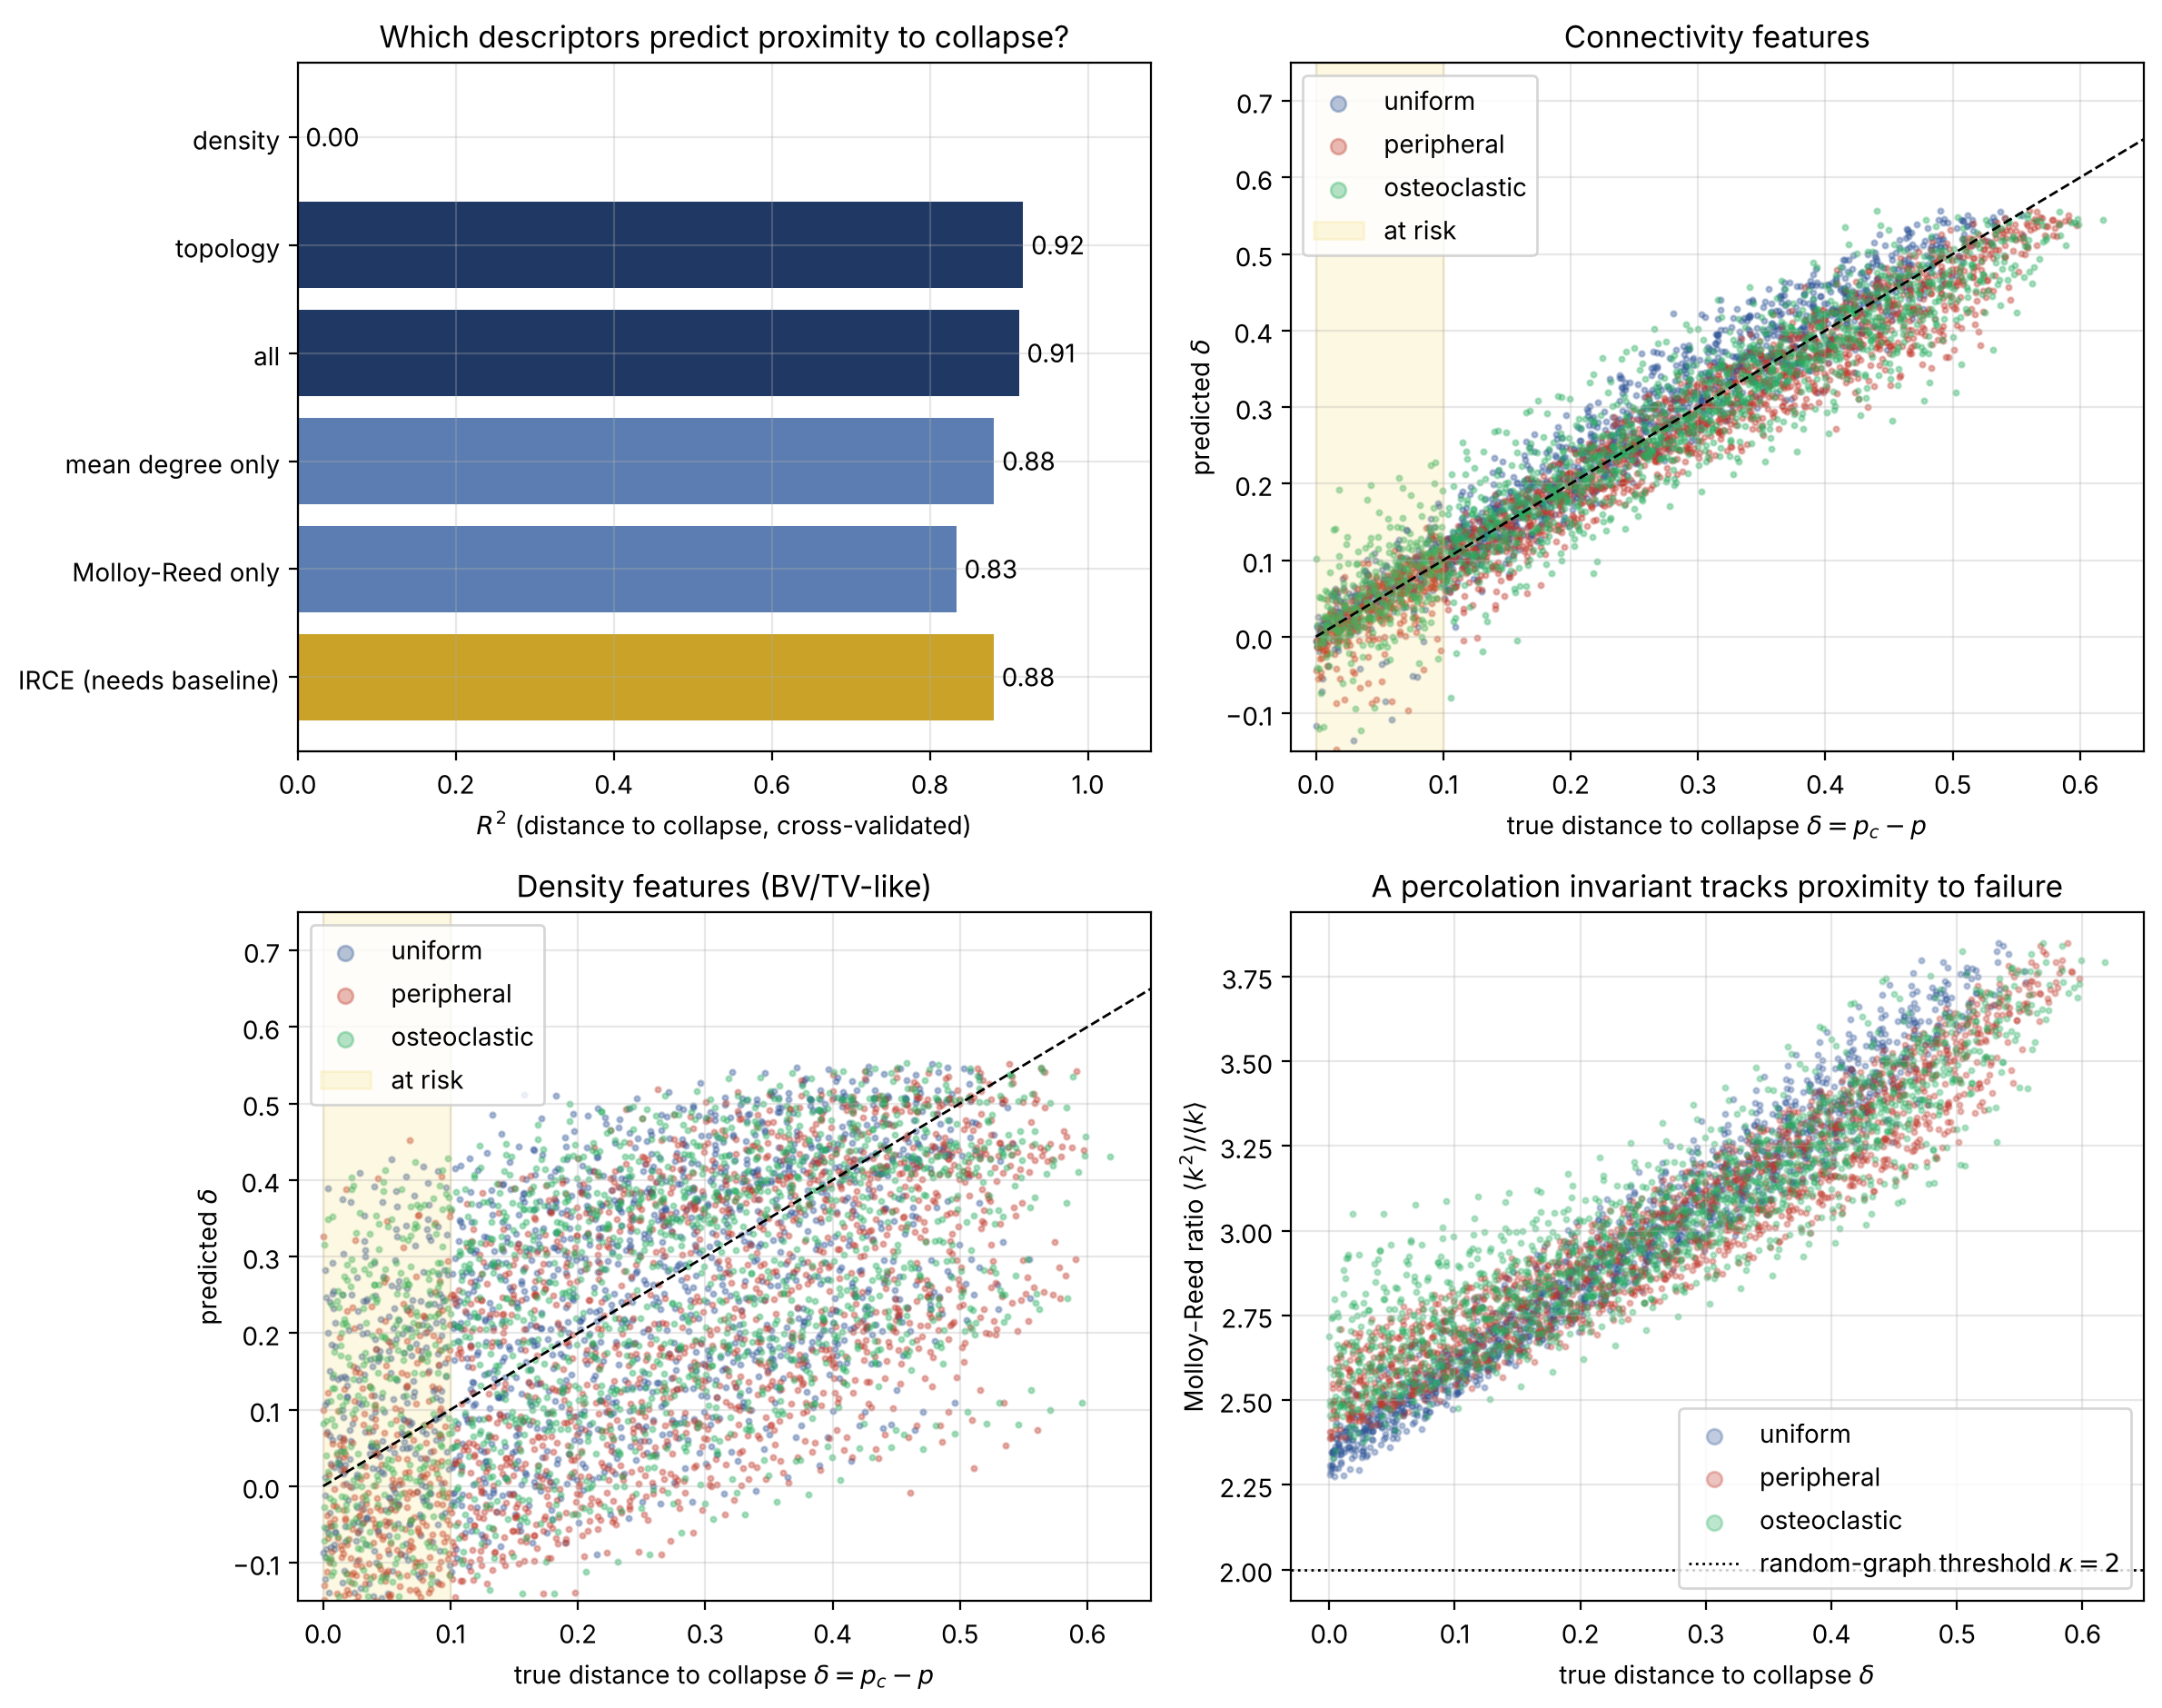

In [7]:
colors = {"uniform": "#2f5597", "peripheral": "#c0392b", "osteoclastic": "#27ae60"}
connected = df[df.delta >= 0]
pred_topo = cross_validated_predictions(df, FEATURE_SETS["topology"])
pred_dens = cross_validated_predictions(df, FEATURE_SETS["density"])
mask = (df.delta >= 0).to_numpy()

fig, axes = plt.subplots(2, 2, figsize=(12, 9.5))

ax = axes[0, 0]
order = ["density", "topology", "all", "mean degree only", "Molloy-Reed only", "IRCE (needs baseline)"]
vals = results.loc[order, "R2"].clip(lower=0)
bar_colors = ["#999999", "#1f3864", "#1f3864", "#5b7db1", "#5b7db1", "#c9a227"]
ax.barh(order[::-1], vals[::-1], color=bar_colors[::-1])
for i, v in enumerate(vals[::-1]):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center")
ax.set(xlim=(0, 1.08), xlabel=r"$R^2$ (distance to collapse, cross-validated)",
       title="Which descriptors predict proximity to collapse?")

for ax, pred, title in [(axes[0, 1], pred_topo, "Connectivity features"),
                        (axes[1, 0], pred_dens, "Density features (BV/TV-like)")]:
    for reg, c in colors.items():
        m = mask & (df.regime == reg).to_numpy()
        ax.scatter(df.delta[m], pred[m], s=4, alpha=0.35, color=c, label=reg)
    ax.plot([0, 0.65], [0, 0.65], "k--", lw=1)
    ax.axvspan(0, AT_RISK_WINDOW, color="#f4d03f", alpha=0.15, label="at risk")
    ax.set(xlabel=r"true distance to collapse $\delta = p_c - p$",
           ylabel=r"predicted $\delta$", title=title, xlim=(-0.02, 0.65), ylim=(-0.15, 0.75))
    ax.legend(markerscale=3, loc="upper left")

ax = axes[1, 1]
for reg, c in colors.items():
    d = connected[connected.regime == reg]
    ax.scatter(d.delta, d.molloy_reed, s=4, alpha=0.3, color=c, label=reg)
ax.axhline(2.0, color="k", ls=":", lw=1, label=r"random-graph threshold $\kappa = 2$")
ax.set(xlabel=r"true distance to collapse $\delta$",
       ylabel=r"Molloy–Reed ratio $\langle k^2\rangle/\langle k\rangle$",
       title="A percolation invariant tracks proximity to failure")
ax.legend(markerscale=3, loc="lower right")

for ax in axes.flat:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_early_warning.png", dpi=150)
plt.show()

## 7. Interpretation and limitations

* **Density-based descriptors do not predict proximity to collapse** once individuals differ in strut thickness and cell size: two networks with the same BV/TV can be at very different distances from the transition.
* **Connectivity descriptors do**, from a single snapshot and without a healthy baseline, and they transfer to an erosion regime not seen in training. This supports prediction 2 of the IRCE framework.
* The dominant signal is the **node-degree distribution** (mean degree, dangling ends, Molloy–Reed ratio), consistent with percolation theory. The transition occurs at $\kappa \approx 2.5$ rather than the value 2 for tree-like random graphs, as expected for spatially embedded networks with loops.

**Limitations.** All data are synthetic (Voronoi networks with edge-removal erosion). Erosion removes struts but does not thin them; real RA also involves trabecular thinning. Validation requires graph extraction from real micro-CT / HR-pQCT volumes (roadmap v0.4.0), where node degree is measurable by skeletonization.